# Analyse du dataset `asl_selected.csv`

Ce notebook analyse le dataset après le filtrage des vidéos réellement disponibles.

Objectifs :
- vérifier le nombre total de vidéos ;
- vérifier le nombre de classes ;
- analyser le nombre de vidéos par classe ;
- repérer les classes peu représentées ;
- analyser la répartition `train / val / test` ;
- vérifier la répartition des splits pour chaque classe.


## 1. Importer les bibliothèques

`pandas` sert à lire et analyser le CSV. `matplotlib` sert à afficher les graphiques. `Path` sert à gérer les chemins.


In [13]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt


## 2. Charger `asl_selected.csv`

On force `video_id` à être du texte pour conserver les zéros au début des identifiants.


In [14]:
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

CSV_PATH = ROOT / "data" / "asl" / "asl_selected.csv"

df = pd.read_csv(CSV_PATH, dtype={"video": str})
df.head()


,video,gloss,split
0,69241.mp4,BOOK,train
1,68011.mp4,BOOK,train
2,68012.mp4,BOOK,train
3,70212.mp4,BOOK,val
4,70266.mp4,BOOK,train


## 3. Informations générales

On vérifie la taille du dataset et le nombre de classes différentes.


In [15]:
print("Nombre total de vidéos :", len(df))
print("Nombre de classes :", df["gloss"].nunique())
print("Colonnes :", list(df.columns))


Nombre total de vidéos : 1137
Nombre de classes : 100
Colonnes : ['video', 'gloss', 'split']


## 4. Nombre de vidéos pour chaque classe

`value_counts()` compte combien de fois chaque `gloss` apparaît. Comme une ligne correspond à une vidéo, cela donne le nombre de vidéos par classe.


In [16]:
videos_par_classe = df["gloss"].value_counts()
videos_par_classe


gloss
COMPUTER    18
DRINK       16
BEFORE      16
LIKE        16
HOT         15
            ..
TABLE        8
CHEAT        8
MEDICINE     8
HELP         7
TELL         7
Name: count, Length: 100, dtype: int64

## 5. Les classes les plus et les moins représentées


In [17]:
print("10 classes avec le plus de vidéos :")
display(videos_par_classe.head(10))

print("10 classes avec le moins de vidéos :")
display(videos_par_classe.tail(10))


10 classes avec le plus de vidéos :


gloss
COMPUTER    18
DRINK       16
BEFORE      16
LIKE        16
HOT         15
ORANGE      15
WHO         14
DEAF        14
YES         14
MOTHER      14
Name: count, dtype: int64

10 classes avec le moins de vidéos :


gloss
TIME        9
JACKET      9
SAME        9
SON         9
THURSDAY    9
TABLE       8
CHEAT       8
MEDICINE    8
HELP        7
TELL        7
Name: count, dtype: int64

## 6. Statistiques sur le nombre de vidéos par classe

On calcule le minimum, le maximum, la moyenne et la médiane pour voir si les classes sont équilibrées.


In [18]:
print("Minimum :", videos_par_classe.min())
print("Maximum :", videos_par_classe.max())
print("Moyenne :", round(videos_par_classe.mean(), 2))
print("Médiane :", videos_par_classe.median())


Minimum : 7
Maximum : 18
Moyenne : 11.37
Médiane : 11.0


## 7. Graphique : nombre de vidéos par classe

Ce graphique permet de comparer visuellement toutes les classes.


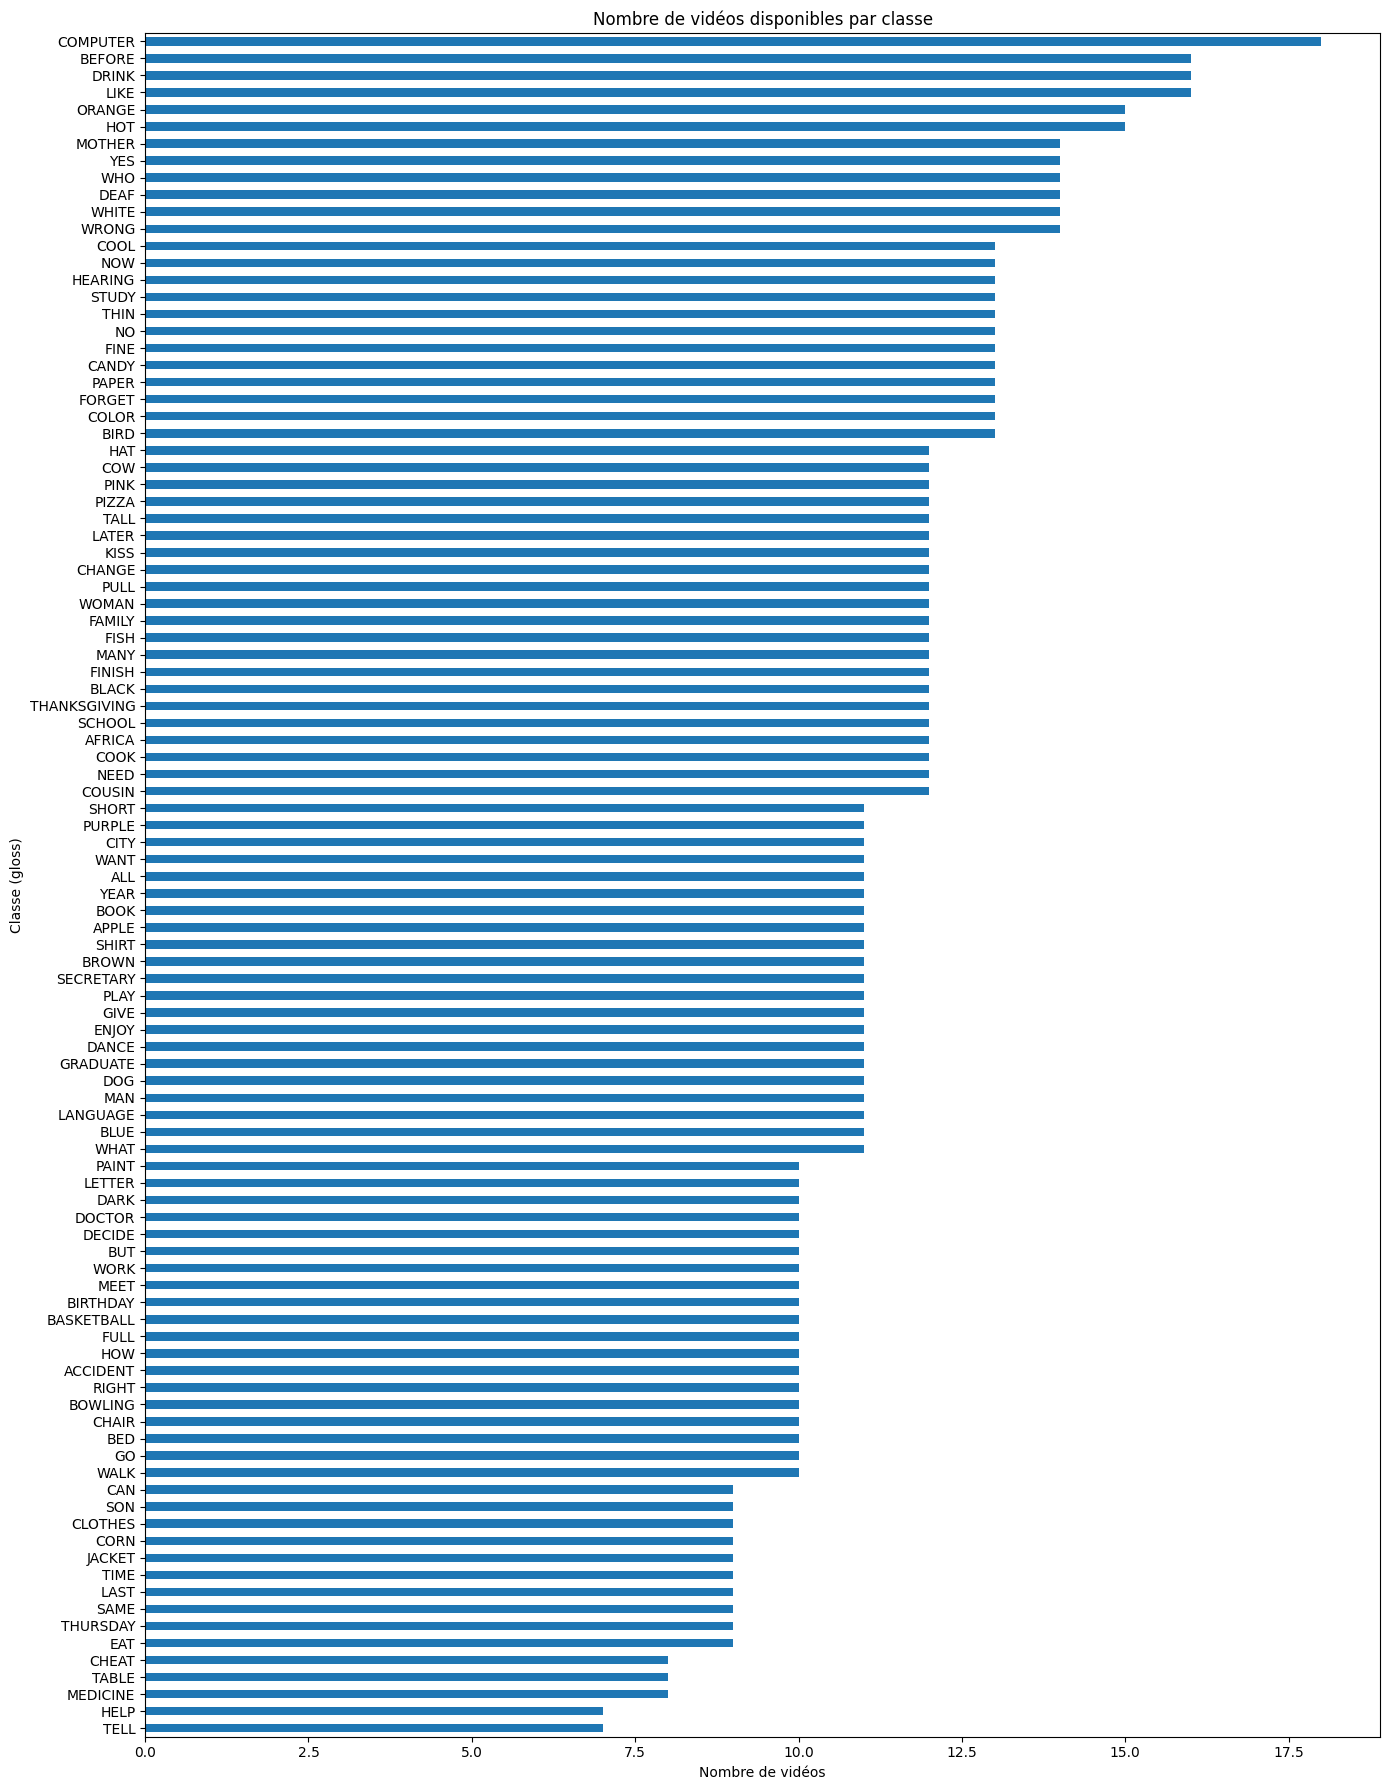

In [19]:
plt.figure(figsize=(14, 18))
videos_par_classe.sort_values().plot(kind="barh")
plt.xlabel("Nombre de vidéos")
plt.ylabel("Classe (gloss)")
plt.title("Nombre de vidéos disponibles par classe")
plt.tight_layout()
plt.show()


## 8. Répartition train / val / test

On compte le nombre de vidéos dans chaque split.


In [20]:
split_counts = df["split"].value_counts()
split_counts


split
train    767
val      197
test     173
Name: count, dtype: int64

In [21]:
split_percent = (df["split"].value_counts(normalize=True) * 100).round(2)
split_percent


split
train    67.46
val      17.33
test     15.22
Name: proportion, dtype: float64

## 9. Répartition des splits pour chaque classe

Cette table montre, pour chaque `gloss`, combien de vidéos sont dans `train`, `val` et `test`.


In [22]:
repartition_classe_split = pd.crosstab(df["gloss"], df["split"])
repartition_classe_split


split,test,train,val
gloss,,,
ACCIDENT,2,6,2
AFRICA,2,8,2
ALL,2,6,3
APPLE,1,8,2
BASKETBALL,2,7,1
...,...,...,...
WOMAN,3,7,2
WORK,2,7,1
WRONG,2,10,2


## 10. Classes potentiellement fragiles

On affiche les classes avec moins de 10 vidéos. Ce seuil sert seulement à l'analyse : il ne veut pas dire automatiquement qu'il faut supprimer ces classes.


In [23]:
classes_moins_10 = videos_par_classe[videos_par_classe < 10]
print("Nombre de classes avec moins de 10 vidéos :", len(classes_moins_10))
classes_moins_10


Nombre de classes avec moins de 10 vidéos : 15


gloss
CLOTHES     9
CAN         9
CORN        9
EAT         9
LAST        9
TIME        9
JACKET      9
SAME        9
SON         9
THURSDAY    9
TABLE       8
CHEAT       8
MEDICINE    8
HELP        7
TELL        7
Name: count, dtype: int64

## 11. Vérifier les valeurs manquantes et les doublons

Avant de continuer, on vérifie que le CSV ne contient pas de valeur manquante et qu'une même vidéo n'apparaît pas plusieurs fois.


In [24]:
print("Valeurs manquantes par colonne :")
print(df.isna().sum())

print("\nNombre de vidéos dupliquées :", df["video"].duplicated().sum())


Valeurs manquantes par colonne :
video    0
gloss    0
split    0
dtype: int64

Nombre de vidéos dupliquées : 0


## 12. Visualiser la répartition globale des splits

Ce graphique permet de comparer rapidement le nombre de vidéos utilisées pour l'entraînement, la validation et le test.


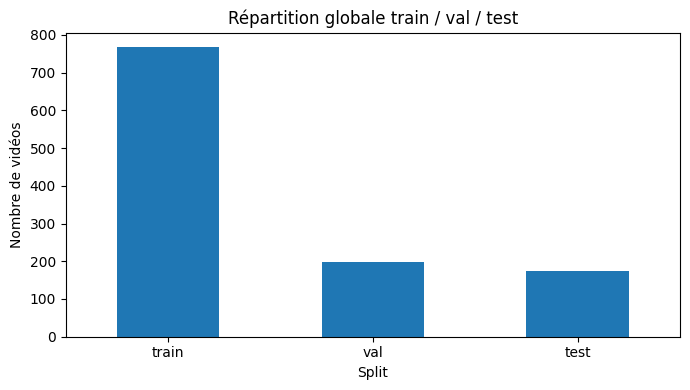

In [25]:
plt.figure(figsize=(7, 4))
split_counts.plot(kind="bar")
plt.xlabel("Split")
plt.ylabel("Nombre de vidéos")
plt.title("Répartition globale train / val / test")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 13. Vérifier si chaque classe existe dans train, val et test

Une classe peut encore exister dans le dataset mais avoir perdu toutes ses vidéos de validation ou de test après le filtrage des vidéos indisponibles.

On cherche donc les classes pour lesquelles au moins un des trois splits contient `0` vidéo.


In [26]:
classes_split_manquant = repartition_classe_split[
    (repartition_classe_split == 0).any(axis=1)
]

print(
    "Nombre de classes avec au moins un split vide :",
    len(classes_split_manquant)
)

classes_split_manquant


Nombre de classes avec au moins un split vide : 10


split,test,train,val
gloss,,,
BED,2,8,0
BOOK,0,9,2
CHEAT,0,7,1
DOCTOR,0,7,3
LATER,0,9,3
MEDICINE,0,7,1
SHIRT,0,9,2
SHORT,0,8,3
TELL,2,5,0


### Interprétation des splits manquants

Dans le dataset actuel, **10 classes sur 100** ont au moins un split vide :

- `BED` : aucune vidéo dans `val` ;
- `BOOK` : aucune vidéo dans `test` ;
- `CHEAT` : aucune vidéo dans `test` ;
- `DOCTOR` : aucune vidéo dans `test` ;
- `LATER` : aucune vidéo dans `test` ;
- `MEDICINE` : aucune vidéo dans `test` ;
- `SHIRT` : aucune vidéo dans `test` ;
- `SHORT` : aucune vidéo dans `test` ;
- `TELL` : aucune vidéo dans `val` ;
- `THANKSGIVING` : aucune vidéo dans `test`.

Cela ne signifie pas que ces classes doivent être supprimées. Cela signifie surtout que les **splits d'origine ne sont plus complets après le filtrage** des vidéos indisponibles.


## 14. Résumé automatique du dataset

Cette cellule regroupe les principales statistiques obtenues dans le notebook.


In [27]:
print("========== RÉSUMÉ DU DATASET ==========")
print("Nombre total de vidéos :", len(df))
print("Nombre de classes :", df["gloss"].nunique())
print("Minimum de vidéos par classe :", videos_par_classe.min())
print("Maximum de vidéos par classe :", videos_par_classe.max())
print("Moyenne de vidéos par classe :", round(videos_par_classe.mean(), 2))
print("Médiane :", videos_par_classe.median())
print("Classes avec moins de 10 vidéos :", len(classes_moins_10))
print("Classes avec au moins un split vide :", len(classes_split_manquant))

print("\nRépartition globale :")
for split, nombre in split_counts.items():
    pourcentage = split_percent[split]
    print(f"{split} : {nombre} vidéos ({pourcentage} %)")


========== RÉSUMÉ DU DATASET ==========
Nombre total de vidéos : 1137
Nombre de classes : 100
Minimum de vidéos par classe : 7
Maximum de vidéos par classe : 18
Moyenne de vidéos par classe : 11.37
Médiane : 11.0
Classes avec moins de 10 vidéos : 15
Classes avec au moins un split vide : 10

Répartition globale :
train : 767 vidéos (67.46 %)
val : 197 vidéos (17.33 %)
test : 173 vidéos (15.22 %)


# Conclusion de l'analyse initiale

Après le téléchargement et le filtrage des vidéos réellement disponibles, le dataset `asl_selected.csv` contient **1137 vidéos** réparties sur **100 classes**.

Le nombre de vidéos par classe varie de **7 à 18**, avec une moyenne de **11,37 vidéos** et une médiane de **11 vidéos**. Les classes sont donc toutes encore présentes, mais leur représentation n'est pas parfaitement équilibrée. **15 classes** possèdent moins de 10 vidéos.

La répartition globale est :

- **train : 767 vidéos (67,46 %)**
- **validation : 197 vidéos (17,33 %)**
- **test : 173 vidéos (15,22 %)**

L'analyse classe par classe montre cependant que **10 classes ont au moins un split vide**. Deux classes (`BED` et `TELL`) n'ont aucune vidéo de validation, tandis que huit classes (`BOOK`, `CHEAT`, `DOCTOR`, `LATER`, `MEDICINE`, `SHIRT`, `SHORT` et `THANKSGIVING`) n'ont aucune vidéo de test.

**Conclusion générale :** `asl_selected.csv` représente correctement les vidéos réellement disponibles et peut être conservé comme fichier de référence. En revanche, avant l'entraînement final du modèle, il faudra décider comment traiter les classes dont un split est vide : récupérer d'autres vidéos ou créer un nouveau découpage `train / val / test` dans un fichier séparé, sans modifier `asl_selected.csv`.

La prochaine étape du pipeline peut ensuite être la **vérification de la qualité et de la lisibilité des vidéos**, avant l'extraction des keypoints avec MediaPipe.


# Décision méthodologique après cette analyse

Cette première expérience avec `WLASL100` nous a permis d'identifier plusieurs limites importantes du dataset actuel :

- `asl_raw.csv` contenait **2038 instances théoriques** ;
- après téléchargement et preprocessing, `asl_selected.csv` contient **1137 vidéos réellement disponibles** ;
- les **100 classes sont encore présentes**, mais elles ne sont pas toutes aussi bien représentées ;
- le nombre de vidéos par classe varie de **7 à 18** ;
- **15 classes** ont moins de 10 vidéos ;
- **10 classes** ont au moins un split `train`, `val` ou `test` vide.

Ces observations montrent que les 100 classes actuelles ne doivent pas être considérées automatiquement comme les 100 classes finales du projet.

## Décision prise

L'objectif devient de construire, à partir de **WLASL complet**, un dataset final contenant **100 classes de la meilleure qualité possible pour notre projet**.

Nous ne voulons donc pas conserver une classe uniquement parce qu'elle appartient à `WLASL100`.

Une classe sera retenue seulement si elle satisfait des critères de qualité suffisants après vérification réelle des vidéos.

## Ordre des prochaines étapes

```text
asl_selected.csv
1137 vidéos disponibles
        |
        v
DATA CLEANING
        |
        |-- vidéo lisible par OpenCV ?
        |-- nombre de frames valide ?
        |-- FPS valide ?
        |-- résolution exploitable ?
        |-- durée exploitable ?
        |-- vidéo non corrompue ?
        |-- qualité visuelle suffisante ?
        |-- mains / corps suffisamment visibles ?
        |
        v
asl_clean.csv
        |
        v
ANALYSE APRÈS CLEANING
        |
        |-- nombre de bonnes vidéos par classe
        |-- diversité des signants si disponible
        |-- classes faibles
        |-- splits vides
        |-- qualité globale de chaque classe
        |
        v
ÉTUDE DE WLASL COMPLET
        |
        |-- chercher de nouvelles vidéos pour une classe faible
        |-- ou remplacer une classe trop faible
        |   par une classe WLASL plus robuste
        |
        v
APPLICATION DES CONDITIONS DE SÉLECTION
        |
        |-- assez de vidéos propres
        |-- diversité suffisante des signants
        |-- vidéos réellement exploitables
        |-- détection mains/corps suffisamment bonne
        |-- possibilité de construire train / val / test
        |-- éviter une classe dépendante d'un seul signant
        |
        v
SÉLECTION DES 100 MEILLEURES CLASSES
        |
        v
asl_final.csv
        |
        v
SPLIT FINAL train / val / test
        |
        v
MediaPipe -> keypoints -> LSTM
```

## Règle importante

Les seuils définitifs de sélection ne sont **pas encore fixés**.

Par exemple, nous ne décidons pas maintenant qu'une classe avec moins de 10 vidéos doit être automatiquement supprimée.

Les seuils seront définis **après le data cleaning et l'analyse de WLASL complet**, afin de choisir des règles basées sur les données réellement disponibles.

## Statut de `asl_selected.csv`

`asl_selected.csv` reste un **fichier de référence de notre première expérimentation**.

Il ne sera pas modifié pour fabriquer artificiellement un meilleur dataset.

Les étapes suivantes créeront de nouveaux fichiers :

```text
asl_raw.csv
    -> dataset théorique initial

asl_selected.csv
    -> vidéos réellement disponibles de la première sélection

asl_clean.csv
    -> vidéos de la première sélection qui passent le data cleaning

asl_candidates.csv
    -> classes et vidéos candidates provenant de WLASL complet

asl_final.csv
    -> dataset final avec les 100 classes retenues
```

## Objectif final

Construire un dataset de **100 classes robustes, propres, suffisamment représentées et réellement exploitables**, plutôt que conserver obligatoirement les 100 classes initiales de WLASL100.
